<div dir="rtl">

# מטלת ביניים: ניתוח גישושי לנתוני טויוטה קורולה
**נושא 8, קונה פרטי:** תיבה אוטומטית, האם משלמים עליה?

<div style="text-align:center;">
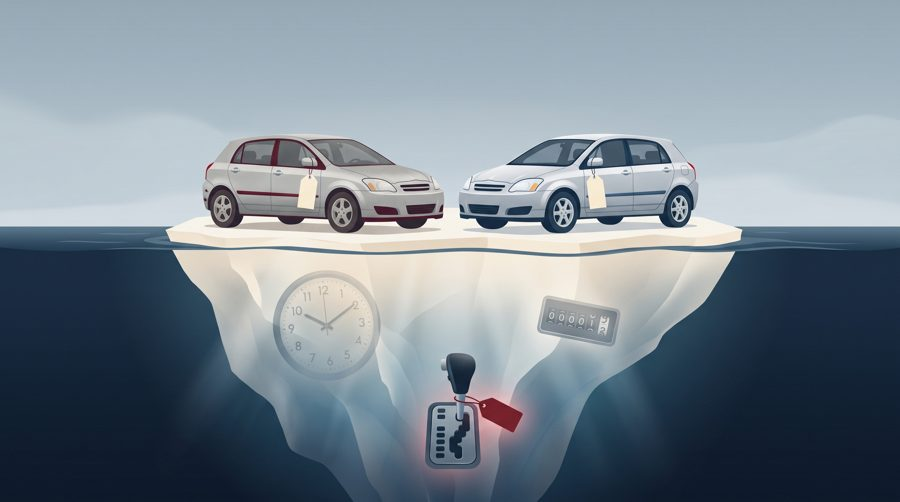
<br>
<sub>איור להמחשת הממצא (נוצר ב־AI): בהשוואה הגולמית המחירים שווים, ומתחת לפני השטח מסתתרים הגיל, הק״מ והפרמיה על התיבה.</sub>
</div>

</div>

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import statsmodels.formula.api as smf
from openpyxl import load_workbook
from statsmodels.nonparametric.smoothers_lowess import lowess

In [2]:
FILE = "Toyota_Corolla_cars.xlsx"
toyota_raw = pd.read_excel(FILE, sheet_name="data")

sns.set_theme(style="whitegrid", font_scale=1.05)
TRANS_COLS = {"Manual": "#3E6A8A", "Automatic": "#A3282C"}
ORDER = ["Manual", "Automatic"]
thousands = mtick.FuncFormatter(lambda x, _: f"{x:,.0f}")  # used for EUR and KM axes

FIG_DIR = Path("figures")  # all graphs are saved here
FIG_DIR.mkdir(exist_ok=True)

def save(fig, name):
    """Tight layout, save to figures/, show."""
    fig.tight_layout()
    fig.savefig(FIG_DIR / name, dpi=150)
    plt.show()

print(toyota_raw.shape)

(1436, 39)


<hr>

<div dir="rtl">

## 1. שאלות המחקר
**הבעיה המחקרית:** קונה פרטי רוצה לדעת אם תיבה אוטומטית עולה יותר בקורולה משומשת, וכמה.

| סוג | שאלה | משתנים בקובץ | מה חסר |
|---|---|---|---|
| תיאור | מהו שיעור הרכבים האוטמטיים לעומת ידניים מכלל הרכבים במדגם, ומהו חציון המחיר של כל קבוצה? | Automatic, Price | |
| קשר | האם קיים קשר בין סוג תיבת ההילוכים למחיר הרכב? | Automatic, Price | |
|  חיזוי |  בהינתן רכב עם מאפיינים ידועים, מה יהיה מחירו? | Price, Age_08_04, KM, HP, Automatic, Weight, Doors, Fuel_Type | מחיר עסקה בפועל, זמן עד מכירה |
| סיבתיות | האם הפער במחיר הוא תוצאה ישירה של סוג הגיר, או שמדובר בהשפעה עקיפה משתנים מתערבים אחרים? | Price, Automatic, Age_08_04, KM, HP, Fuel_Type, Airco, Automatic_airco, ABS, Metallic_Rim, Boardcomputer | אמינות ותקלות, היסטוריית טיפולים ותאונות, מספר בעלים קודמים, סוג המוכר (סוחר או פרטי), רמת גימור מלאה, מצב הרכב |

</div>

<hr>

<div dir="rtl">

## 2. הכנת הנתונים
העבודה עוברת על שבעת השלבים הקלאסיים של פרויקט דאטה. שלבים 1 עד 6 מופיעים בסעיף הזה, ושלב 7 (הכנה למודל) מופיע בסעיף 6, אחרי הניתוח הגישושי.

| שלב | מה בודקים | איפה |
|---|---|---|
| 1. הבנת הנתונים | סוגי עמודות (dtypes), תיאור סטטיסטי (describe) | 2.1 |
| 2. ערכים חסרים | isna().sum(), מחיקה או השלמה | 2.2 |
| 3. תיקון סוגי נתונים | המרה למספר או לקטגוריה, ערכים כמו "NA" או "unknown" בתוך טקסט | 2.3 |
| 4. דאטה "מלוכלך" | רווחים, אותיות גדולות וקטנות, שגיאות כתיב, אחידות תאריכים | 2.4 |
| 5. ערכים קיצוניים | זיהוי, והחלטה אם להסיר, לתקן או להשאיר | 2.5 |
| 6. כפילויות | שורות כפולות, כפילויות לפי מזהה | 2.6 |
| 7. הכנה למודל | קידוד קטגוריות, Scaling, חלוקה ל־Train/Test | סעיף 6 |

</div>

<div dir="rtl">

### 2.1 הבנת הנתונים

</div>

In [3]:
print("Rows:", len(toyota_raw), " Columns:", toyota_raw.shape[1])
print("Column types:", toyota_raw.dtypes.astype(str).value_counts().to_dict())

# All columns used in the research questions and in the cleaning checks
key_cols = ["Id", "Model", "Price", "Automatic", "Age_08_04", "Mfg_Month", "Mfg_Year",
            "KM", "Fuel_Type", "HP", "CC", "Doors", "Gears", "Cylinders", "Weight", "Color",
            "Mfr_Guarantee", "BOVAG_Guarantee", "Guarantee_Period"]
equip_cols = ["ABS", "Airbag_1", "Airbag_2", "Airco", "Automatic_airco", "Boardcomputer",
              "CD_Player", "Central_Lock", "Powered_Windows", "Power_Steering", "Radio",
              "Mistlamps", "Sport_Model", "Metallic_Rim", "Met_Color", "Tow_Bar"]
cols = key_cols + equip_cols
overview = pd.DataFrame({"dtype": toyota_raw[cols].dtypes.astype(str),
                         "n_unique": toyota_raw[cols].nunique(),
                         "example": toyota_raw[cols].iloc[0]})
display(overview)
num_cols = ["Price", "Age_08_04", "Mfg_Year", "KM", "HP", "CC", "Doors", "Weight"]
display(toyota_raw[num_cols].describe().round(1))
# Binary columns (0/1): share of cars with each feature, in %
display((toyota_raw[["Automatic"] + equip_cols].mean() * 100).round(1).to_frame("% of cars"))

Rows: 1436  Columns: 39
Column types: {'int64': 36, 'object': 3}


,dtype,n_unique,example
Id,int64,1436,1
Model,object,372,TOYOTA Corolla 2.0 D4D HATCHB TERRA 2/3-Doors
Price,int64,236,13500
Automatic,int64,2,0
Age_08_04,int64,77,23
Mfg_Month,int64,12,10
Mfg_Year,int64,7,2002
KM,int64,1263,46986
Fuel_Type,object,3,Diesel
HP,int64,12,90


,Price,Age_08_04,Mfg_Year,KM,HP,CC,Doors,Weight
count,1436.0,1436.0,1436.0,1436.0,1436.0,1436.0,1436.0,1436.0
mean,10730.8,55.9,1999.6,68533.3,101.5,1576.9,4.0,1072.5
std,3627.0,18.6,1.5,37506.4,15.0,424.4,1.0,52.6
min,4350.0,1.0,1998.0,1.0,69.0,1300.0,2.0,1000.0
25%,8450.0,44.0,1998.0,43000.0,90.0,1400.0,3.0,1040.0
50%,9900.0,61.0,1999.0,63389.5,110.0,1600.0,4.0,1070.0
75%,11950.0,70.0,2001.0,87020.8,110.0,1600.0,5.0,1085.0
max,32500.0,80.0,2004.0,243000.0,192.0,16000.0,5.0,1615.0


,% of cars
Automatic,5.6
ABS,81.3
Airbag_1,97.1
Airbag_2,72.3
Airco,50.8
Automatic_airco,5.6
Boardcomputer,29.5
CD_Player,21.9
Central_Lock,58.0
Powered_Windows,56.2


<div dir="rtl">

### 2.2 ערכים חסרים

</div>

In [4]:
missing = toyota_raw.isna().sum()
print("Missing values (total):", missing.sum())
if missing.any():
    display(missing[missing > 0].to_frame("missing"))
else:
    print("No column has missing values")

Missing values (total): 0
No column has missing values


<div dir="rtl" style="background-color:#eef3f8; border-right:4px solid #3E6A8A; padding:10px 14px; border-radius:4px;">

**תוצאה:** אין ערכים חסרים באף עמודה, ולכן לא נדרשת מחיקה או השלמה (imputation).

</div>

<div dir="rtl">

### 2.3 תיקון סוגי נתונים
**הבעיה: עמודת CC שמורה בקובץ כטקסט.** pandas ממיר אותה למספר בשקט, ולכן בודקים את סוג התאים ישירות בקובץ.

</div>

In [5]:
ws = load_workbook(FILE, read_only=True)["data"]
header = [c.value for c in next(ws.iter_rows(max_row=1))]
cc_idx = header.index("CC")
cell_types = pd.Series([type(r[cc_idx]).__name__
                        for r in ws.iter_rows(min_row=2, values_only=True)
                        if r[0] is not None])
print("Cell types in CC column:", cell_types.value_counts().to_dict())
print("pandas dtype after reading:", toyota_raw.CC.dtype)

# Placeholder text that should really be a missing value ("NA", "unknown", "?" ...)
obj_cols = toyota_raw.select_dtypes("object").columns
bad_tokens = {"", "na", "n/a", "nan", "null", "none", "unknown", "?", "-"}
for c in obj_cols:
    s = toyota_raw[c].astype(str).str.strip().str.lower()
    print(f"{c}: placeholder-like values = {s.isin(bad_tokens).sum()}")

Cell types in CC column: {'str': 1436}
pandas dtype after reading: int64
Model: placeholder-like values = 0
Fuel_Type: placeholder-like values = 0
Color: placeholder-like values = 0


<div dir="rtl" style="background-color:#eef3f8; border-right:4px solid #3E6A8A; padding:10px 14px; border-radius:4px;">

**תוצאה:** CC שמורה כטקסט בכל 1,436 התאים, ומומרת למספר בשלב הניקוי. בעמודות הטקסט (Model, Fuel_Type, Color) אין ערכים כמו "NA" או "unknown" שמסתירים ערך חסר. Automatic (0/1) מומר לקטגוריה Transmission לצורך הגרפים.

</div>

<div dir="rtl">

### 2.4 דאטה "מלוכלך"

</div>

In [6]:
# Text: extra spaces, upper/lower case variants
for c in obj_cols:
    raw = toyota_raw[c].astype(str)
    clean = raw.str.strip().str.replace(r"\s+", " ", regex=True).str.lower()
    print(f"{c}: {raw.nunique()} unique values, {clean.nunique()} after strip/lower/single spaces")
# Model: where do the extra variants come from?
m = toyota_raw.Model.astype(str)
print("Model rows with leading/trailing spaces (incl. non-breaking \\xa0):", (m != m.str.strip()).sum())
model_clean = m.str.strip().str.replace(r"\s+", " ", regex=True).str.upper()
print("Model unique: raw", m.nunique(), "| after strip", m.str.strip().nunique(),
      "| after strip + upper case", model_clean.nunique())
ms = m.str.strip().drop_duplicates()
case_var = ms.groupby(ms.str.upper()).agg(list)
display(case_var[case_var.str.len() > 1].head(3).to_frame("case variants"))
print("Fuel_Type values:", toyota_raw.Fuel_Type.value_counts().to_dict())

# Dates: is Age_08_04 consistent with the manufacturing month and year?
if {"Mfg_Month", "Mfg_Year"} <= set(toyota_raw.columns):
    age_calc = (2004 - toyota_raw.Mfg_Year) * 12 + (8 - toyota_raw.Mfg_Month)
    print("Age_08_04 minus age from Mfg_Year/Mfg_Month:",
          (toyota_raw.Age_08_04 - age_calc).value_counts().to_dict())

Model: 372 unique values, 312 after strip/lower/single spaces
Fuel_Type: 3 unique values, 3 after strip/lower/single spaces
Color: 10 unique values, 10 after strip/lower/single spaces
Model rows with leading/trailing spaces (incl. non-breaking \xa0): 150
Model unique: raw 372 | after strip 319 | after strip + upper case 312


,case variants
Model,
TOYOTA COROLLA 1.3 HB LINEA TERRA 2/3-DOORS,"[TOYOTA Corolla 1.3 HB LINEA TERRA 2/3-Doors, ..."
TOYOTA COROLLA 1.6 16V LIFTBACK LINEA LUNA 4/5-DOORS,[TOYOTA Corolla 1.6 16v Liftback Linea Luna 4/...
TOYOTA COROLLA 1.6 HATCHBACK 2/3-DOORS,"[TOYOTA Corolla 1.6 Hatchback 2/3-Doors, TOYOT..."


Fuel_Type values: {'Petrol': 1264, 'Diesel': 155, 'CNG': 17}
Age_08_04 minus age from Mfg_Year/Mfg_Month: {1: 1436}


<div dir="rtl" style="background-color:#eef3f8; border-right:4px solid #3E6A8A; padding:10px 14px; border-radius:4px;">

**תוצאה:** בעמודה Model יש 150 ערכים עם רווח מוביל, רובם רווח לא־שביר (`\xa0`), וגם הבדלי אותיות גדולות וקטנות (למשל Liftback מול LIFTBACK). אחרי ניקוי הרווחים ואיחוד האותיות מספר הדגמים יורד מ־372 ל־312. Model לא משמש בניתוח עצמו, אבל מנקים אותו כי בדיקת הכפילויות נשענת עליו. Fuel_Type ו־Color נקיות. התאריכים עקביים: בכל השורות Age_08_04 גדול בחודש אחד בדיוק מהגיל שמחושב מ־Mfg_Year ו־Mfg_Month. זה הפרש קבוע של מוסכמת ספירה, לא טעות.

</div>

<div dir="rtl">

### 2.5 ערכים קיצוניים וחריגים

</div>

In [7]:
# Issue 1: impossible engine size
display(toyota_raw.loc[toyota_raw.CC > 3000, ["Id", "Model", "CC", "HP", "Price"]])
# Issue 2: almost-zero KM
display(toyota_raw.loc[toyota_raw.KM < 100, ["Id", "KM", "Age_08_04", "Price"]])
# Issue 3: constant column
print("Unique values of Cylinders:", toyota_raw.Cylinders.unique())
# Issue 4: price outliers by the IQR rule
q1, q3 = toyota_raw.Price.quantile([.25, .75])
upper = q3 + 1.5 * (q3 - q1)
lower = q1 - 1.5 * (q3 - q1)
print("Price IQR fences:", lower, "-", upper, " cars below:", (toyota_raw.Price < lower).sum(),
      " cars above:", (toyota_raw.Price > upper).sum())
# Issue 5: Weight and HP (both enter the prediction model)
display(toyota_raw[["Weight", "HP"]].describe().round(0).T)
display(toyota_raw.nlargest(3, "Weight")[["Id", "Model", "Weight", "HP", "Fuel_Type", "Price"]])

# Extent of each issue (count and % of all cars)
n = len(toyota_raw)
def pct(k):
    return f"{k} cars ({k / n:.1%})"
print("Price outliers above the fence:", pct((toyota_raw.Price > upper).sum()))
print("KM below 100:", pct((toyota_raw.KM < 100).sum()), "| KM = 1 and older than 24 months:",
      pct(((toyota_raw.KM == 1) & (toyota_raw.Age_08_04 > 24)).sum()))

# Issue 6: near-constant and duplicated columns
for c in ["Parking_Assistant", "Power_Steering"]:
    print(f"{c}: cars with 1 = {toyota_raw[c].sum()} ({toyota_raw[c].mean():.1%})")
print("Radio vs Radio_cassette: rows that differ =", (toyota_raw.Radio != toyota_raw.Radio_cassette).sum())

# Issue 7: is Gears consistent with the transmission type?
display(pd.crosstab(toyota_raw.Gears, toyota_raw.Automatic.map({0: "Manual", 1: "Automatic"})))

# Issue 8: bivariate outliers - price far from the price expected for the car's age
fit = np.polyfit(toyota_raw.Age_08_04, toyota_raw.Price, 2)
resid = toyota_raw.Price - np.polyval(fit, toyota_raw.Age_08_04)
biv = toyota_raw.loc[resid.abs() > 3 * resid.std(), ["Id", "Model", "Age_08_04", "Price", "Automatic"]]
print("Bivariate outliers (price more than 3 SD from the age trend):", pct(len(biv)))
display(biv.assign(Model=biv.Model.str.strip()).sort_values("Price", ascending=False))
is_verso = toyota_raw.Model.str.contains("VERSO", case=False)
print("Verso (MPV) cars:", is_verso.sum(), "| of them automatic:", toyota_raw.loc[is_verso, "Automatic"].sum())

,Id,Model,CC,HP,Price
80,81,TOYOTA Corolla 1.6 5drs 1 4/5-Doors,16000,110,18950


,Id,KM,Age_08_04,Price
109,111,1,4,32500
117,119,1,7,17900
169,171,1,9,17795
170,172,1,9,18245
183,185,15,2,21500
184,186,1,1,17795
185,187,1,1,18245
601,605,1,50,7500
1435,1442,1,76,6950


Unique values of Cylinders: [4]
Price IQR fences: 3200.0 - 17200.0  cars below: 0  cars above: 110


,count,mean,std,min,25%,50%,75%,max
Weight,1436.0,1072.0,53.0,1000.0,1040.0,1070.0,1085.0,1615.0
HP,1436.0,102.0,15.0,69.0,90.0,110.0,110.0,192.0


,Id,Model,Weight,HP,Fuel_Type,Price
221,223,TOYOTA Corolla 1.6 HB LINEA SOL 4/5-Doors,1615,110,Petrol,12450
109,111,TOYOTA Corolla VERSO 2.0 D4D SOL (7) BNS MPV,1480,116,Diesel,32500
110,112,TOYOTA Corolla VERSO 2.0 D4D SOL (7) MPV,1480,116,Diesel,31000


Price outliers above the fence: 110 cars (7.7%)
KM below 100: 9 cars (0.6%) | KM = 1 and older than 24 months: 2 cars (0.1%)
Parking_Assistant: cars with 1 = 4 (0.3%)
Power_Steering: cars with 1 = 1404 (97.8%)
Radio vs Radio_cassette: rows that differ = 3


Automatic,Automatic,Manual
Gears,,
3,2,0
4,1,0
5,76,1314
6,1,42


Bivariate outliers (price more than 3 SD from the age trend): 21 cars (1.5%)


,Id,Model,Age_08_04,Price,Automatic
109,111,TOYOTA Corolla VERSO 2.0 D4D SOL (7) BNS MPV,4,32500,0
111,113,TOYOTA Corolla VERSO 2.0 D4D SOL (7) MPV,4,31275,0
110,112,TOYOTA Corolla VERSO 2.0 D4D SOL (7) MPV,4,31000,0
147,149,TOYOTA Corolla 1.6 16V VVT I 5DR EXEC BNS 4/5-...,13,24500,0
141,143,TOYOTA Corolla 1.8 VVTL-i T-Sport 3-Drs 4/5-Doors,19,23950,0
16,17,TOYOTA Corolla 1.8 16V VVTLI 3DR T SPORT 2/3-D...,30,22750,0
14,15,TOYOTA Corolla 1.8 16V VVTLI 3DR T SPORT 2/3-D...,32,22500,0
68,69,TOYOTA Corolla 2.0 D4D 110 5DR SOL 4/5-Doors,22,22250,0
15,16,TOYOTA Corolla 1.8 16V VVTLI 3DR T SPORT 2/3-D...,28,22000,0
49,50,TOYOTA Corolla 1.8 16V VVTLI 5DR T SPORT 4/5-D...,31,21950,0


Verso (MPV) cars: 5 | of them automatic: 0


<div dir="rtl">

### 2.6 כפילויות

</div>

In [8]:
print("Duplicate rows (all columns except Id):", toyota_raw.drop(columns="Id").duplicated().sum())
print("Duplicate Id values:", toyota_raw.Id.duplicated().sum())
same_car = ["Model", "Price", "Age_08_04", "KM", "HP"]
print("Same car listed twice (same model, price, age, KM, HP):",
      toyota_raw.assign(Model=model_clean).duplicated(subset=same_car).sum())
dup = toyota_raw.assign(Model=model_clean).duplicated(subset=same_car, keep=False)
display(toyota_raw.loc[dup, ["Id"] + same_car + ["Color", "Fuel_Type", "Automatic", "Doors", "Mfg_Year"]])
pair = toyota_raw.loc[dup]
print("Columns that differ between the two rows:",
      [c for c in toyota_raw.columns if pair[c].nunique() > 1])
print("Id range:", toyota_raw.Id.min(), "-", toyota_raw.Id.max(),
      "-> missing Ids:", toyota_raw.Id.max() - len(toyota_raw))

Duplicate rows (all columns except Id): 0
Duplicate Id values: 0
Same car listed twice (same model, price, age, KM, HP): 1


,Id,Model,Price,Age_08_04,KM,HP,Color,Fuel_Type,Automatic,Doors,Mfg_Year
112,114,TOYOTA Corolla VERSO 2.0 D4D LINEA SOL MPV,24950,8,13253,116,Grey,Diesel,0,5,2004
113,115,TOYOTA Corolla VERSO 2.0 D4D LINEA SOL MPV,24950,8,13253,116,Grey,Diesel,0,5,2004


Columns that differ between the two rows: ['Id', 'Model']
Id range: 1 - 1442 -> missing Ids: 6


<div dir="rtl" style="background-color:#faf3f3; border-right:4px solid #A3282C; padding:10px 14px; border-radius:4px;">

### יומן בעיות והחלטות
| בעיה | מיקום | היקף | החלטה ונימוק |
|---|---|---|---|
| ערכים חסרים | כל העמודות | 0 | אין צורך בהשלמה (אבל ראו חוסר מוסווה בק"מ). |
| CC שמור כטקסט | עמודת CC | כל 1,436 התאים (100%) | ממירים למספר לפני כל חישוב. |
| נפח מנוע לא אפשרי | CC, רכב 81 | רכב אחד (0.1%) | שגיאת הקלדה: שם הדגם מציין 1.6 ליטר ו־110 כ"ס מתאימים למנוע כזה. מתקנים ל־1,600. |
| רווחים ואותיות בשם הדגם | Model | 150 רכבים (10.4%) עם רווח מוביל, רובו `\xa0` | מנקים רווחים ומאחדים לאותיות גדולות: 372 דגמים הופכים ל־312. |
| אותו רכב פעמיים | רכבים 114 ו־115 | זוג אחד | זהים בכל העמודות חוץ מ־Id ורווח בשם, כנראה מודעה כפולה. מוחקים את 115 (רכב ידני, לא משפיע על הפרמיה). |
| ק"מ כמעט אפס | KM | 9 רכבים (0.6%) מתחת ל־100 ק"מ | 7 מהם צעירים מ־10 חודשים, כנראה רכבי תצוגה. סביר, משאירים. |
| ק"מ = 1 ברכב ישן (חוסר מוסווה) | רכבים 605 ו־1442, בני 50 ו־76 חודשים | 2 רכבים (0.1%) | כנראה ערך חסר שקודד כ־1. שניהם ידניים, ולכן מסמנים ב־`km_suspect` במקום להחליף ב־NA, ובודקים בסעיף 4 שהפרמיה לא משתנה בלעדיהם. |
| משקל לא סביר | Weight, רכב 223 | רכב אחד (0.1%): 1,615 ק"ג מול חציון 1,070 | כנראה טעות, אבל הערך הנכון לא ידוע. משאירים ומסמנים ב־`weight_suspect`. |
| משתנה קבוע | Cylinders | כל הרכבים = 4 | אין שונות, מוחקים. |
| משתנים כמעט קבועים וכפולים | Parking_Assistant, Power_Steering, Radio ו־Radio_cassette | חיישני חניה ב־4 רכבים (0.3%), הגה כוח ב־97.8%, Radio ו־Radio_cassette שונים רק ב־3 רכבים | כמעט אין בהם מידע. לא נכנסים למודל, ומהזוג Radio ו־Radio_cassette משאירים רק את Radio. |
| מספר הילוכים לא עקבי | Gears מול Automatic | 76 מתוך 80 אוטומטיים רשומים עם 5 הילוכים, כמו הידניים, ורק 3 עם 3 או 4 | ייתכן שרוב ה"אוטומטיים" הם תיבה רובוטית ולא אוטומט קלאסי. אי אפשר לבדוק זאת בקובץ, ולכן זו מגבלה (סעיף 8). |
| חריגי מחיר | Price | 110 רכבים (7.7%) מעל 17,200 €, אף רכב מתחת ל־3,200 € | רכבים צעירים ויקרים אמיתיים, משאירים. |
| חריגים דו־ממדיים | מחיר רחוק מהמגמה לפי גיל (יותר מ־3 סטיות תקן) | 21 רכבים (1.5%): 14 יקרים מהצפוי (Verso, T-Sport) ו־7 זולים מהצפוי | כולם ידניים, ולכן הם לא יוצרים את הפרמיה. ה־Verso (5 רכבים, אף אחד לא אוטומט) הוא רכב משפחתי ואולי מחוץ לאוכלוסיית המחקר. השארתו מעלה את מחיר הידניים הצעירים, כך שאם בכלל, היא מקטינה את הפרמיה. משאירים. |

</div>

In [9]:
toyota = toyota_raw.copy()
toyota["Model"] = model_clean
toyota = toyota[~toyota.duplicated(subset=same_car)].copy()  # same car listed twice
toyota["CC"] = pd.to_numeric(toyota.CC)
toyota.loc[toyota.CC > 3000, "CC"] = 1600
toyota["km_suspect"] = (toyota.KM < 100) & (toyota.Age_08_04 > 24)
toyota["weight_suspect"] = toyota.Weight > 1500  # Id 223: 1,615 kg hatchback
toyota["km_per_month"] = toyota.KM / toyota.Age_08_04  # derived: how much the car is driven
toyota["Transmission"] = pd.Categorical(
    np.where(toyota.Automatic == 1, "Automatic", "Manual"), categories=ORDER)
toyota["Age_band"] = pd.cut(toyota.Age_08_04, [0, 24, 48, 60, 70, 80],
                            labels=["0-24", "25-48", "49-60", "61-70", "71-80"])
toyota["KM_band"] = pd.cut(toyota.KM, [-1, 50000, 100000, 150000, np.inf],
                           labels=["0-50K", "50-100K", "100-150K", "150K+"])
toyota = toyota.drop(columns="Cylinders")
print("Suspicious KM flagged:", toyota.km_suspect.sum(), "| Suspicious weight flagged:", toyota.weight_suspect.sum())

Suspicious KM flagged: 2 | Suspicious weight flagged: 1


<hr>

<div dir="rtl">

## 3. שאלת התיאור

</div>

In [10]:
print(toyota.Transmission.value_counts())
print((toyota.Transmission.value_counts(normalize=True) * 100).round(1))

desc = toyota.groupby("Transmission", observed=True).agg(
    n=("Price", "size"), median_price=("Price", "median"),
    mean_price=("Price", "mean"), median_age=("Age_08_04", "median"),
    median_km=("KM", "median"), median_hp=("HP", "median")).round(0)
display(desc)
display(pd.crosstab(toyota.HP, toyota.Transmission))
display(pd.crosstab(toyota.Fuel_Type, toyota.Transmission))

Transmission
Manual       1355
Automatic      80
Name: count, dtype: int64
Transmission
Manual       94.4
Automatic     5.6
Name: proportion, dtype: float64


,n,median_price,mean_price,median_age,median_km,median_hp
Transmission,,,,,,
Manual,1355,9900.0,10691.0,60.0,64000.0,110.0
Automatic,80,9950.0,11225.0,65.0,56811.0,107.0


Transmission,Manual,Automatic
HP,,
69,34,0
71,1,0
72,73,0
73,1,0
86,226,23
90,36,0
97,164,0
98,2,0
107,0,21


Transmission,Manual,Automatic
Fuel_Type,,
CNG,16,1
Diesel,154,0
Petrol,1185,79


<div dir="rtl" style="background-color:#eef3f8; border-right:4px solid #3E6A8A; padding:10px 14px; border-radius:4px;">

**תובנה:** ההספק וסוג הדלק קשורים לתיבה. מנוע 107 כ"ס מופיע רק באוטומטיים, ואין אף אוטומט בדיזל (שתי הטבלאות האחרונות). לכן ההשוואה ההוגנת בסעיף 4 מסוננת לבנזין 86 עד 110 כ"ס, וגם שם לקבוצת ה־107 כ"ס אין מקבילה ידנית.

</div>

<div dir="rtl">

**גרף 1:** תרשים קופסה של המחיר לפי סוג התיבה, לכל הרכבים במדגם. הקו בתוך הקופסה הוא החציון, היהלום הלבן הוא הממוצע והנקודות הן חריגים. הגרף עונה על שאלת התיאור: האם יש הבדל במחיר בין הקבוצות בלי שום בקרה.

</div>

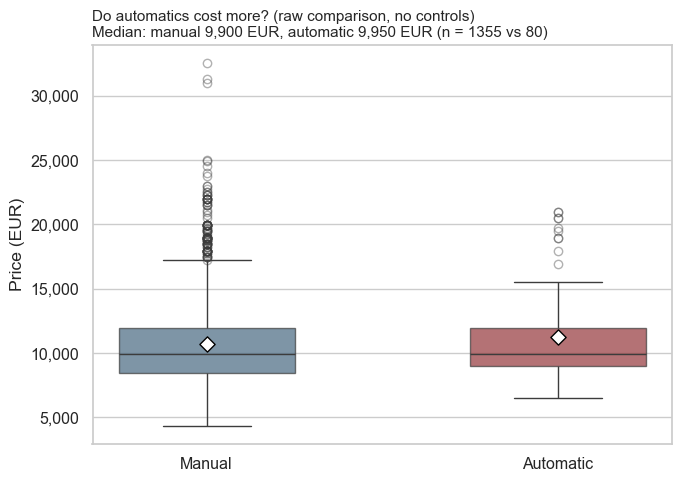

In [11]:
# Graph 1: raw price comparison (looks like no difference)
fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(data=toyota, x="Transmission", y="Price", order=ORDER,
            hue="Transmission", palette=TRANS_COLS, width=0.5,
            boxprops=dict(alpha=0.7), flierprops=dict(alpha=0.4), ax=ax)
means = toyota.groupby("Transmission", observed=True).Price.mean()
ax.scatter(range(2), means[ORDER], marker="D", color="white",
           edgecolor="black", s=60, zorder=5)
ax.yaxis.set_major_formatter(thousands)
ax.set(xlabel=None, ylabel="Price (EUR)")
ax.set_title("Do automatics cost more? (raw comparison, no controls)\n"
             f"Median: manual {desc.median_price['Manual']:,.0f} EUR, "
             f"automatic {desc.median_price['Automatic']:,.0f} EUR "
             f"(n = {desc.n['Manual']:.0f} vs {desc.n['Automatic']:.0f})",
             loc="left", fontsize=11)
save(fig, "g1_raw_price.png")

<div dir="rtl" style="background-color:#eef3f8; border-right:4px solid #3E6A8A; padding:10px 14px; border-radius:4px;">

**תובנה:** בהשוואה הגולמית חציון המחיר כמעט זהה (ידני 9,900 €, אוטומט 9,950 €), כך שבמבט ראשון התיבה האוטומטית לא עולה כלום.

</div>

<div dir="rtl">

**גרף 2:** התפלגות הגיל (בחודשים) של הרכבים הידניים והאוטומטיים, כעקומות צפיפות (KDE). הגרף בודק אם שתי הקבוצות דומות בגיל, ולפניו מודפס המתאם בין המחיר לגיל.

</div>

r(Price, Age) = -0.876


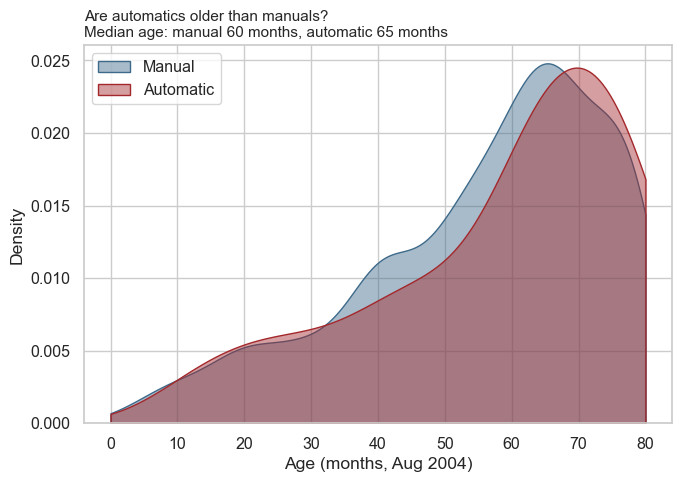

In [12]:
print("r(Price, Age) =", round(toyota.Price.corr(toyota.Age_08_04), 3))

# Graph 2: automatics are older (the hidden third variable)
fig, ax = plt.subplots(figsize=(7, 5))
for t in ORDER:
    sns.kdeplot(toyota.loc[toyota.Transmission == t, "Age_08_04"], fill=True, clip=(0, 80),
                alpha=0.45, color=TRANS_COLS[t], label=t, ax=ax)
ax.set(xlabel="Age (months, Aug 2004)", ylabel="Density")
ax.set_title("Are automatics older than manuals?\n"
             f"Median age: manual {desc.median_age['Manual']:.0f} months, "
             f"automatic {desc.median_age['Automatic']:.0f} months",
             loc="left", fontsize=11)
ax.legend()
save(fig, "g2_age_density.png")

<div dir="rtl" style="background-color:#eef3f8; border-right:4px solid #3E6A8A; padding:10px 14px; border-radius:4px;">

**תובנה:** האוטומטיים מבוגרים יותר מהידניים (חציון 65 חודשים לעומת 60), והגיל הוא המשתנה החזק ביותר למחיר (r = −0.88), ולכן הוא יכול להסתיר פער.

</div>

<hr>

<div dir="rtl">

## 4. שאלת הקשר: בקרה על גיל (משתנה שלישי)

</div>

In [13]:
def premium_table(df, band):
    t = (df.groupby([band, "Transmission"], observed=True).Price.median()
           .unstack())
    t["premium"] = t["Automatic"] - t["Manual"]
    return t

by_age_n = toyota.groupby(["Age_band", "Transmission"], observed=True).size().unstack(fill_value=0)
age_wide = premium_table(toyota, "Age_band")
display(by_age_n)
display(age_wide)

Transmission,Manual,Automatic
Age_band,,
0-24,115,6
25-48,284,15
49-60,279,11
61-70,355,23
71-80,322,25


Transmission,Manual,Automatic,premium
Age_band,,,
0-24,18500.0,20125.0,1625.0
25-48,12497.5,13950.0,1452.5
49-60,10495.0,10950.0,455.0
61-70,8950.0,9750.0,800.0
71-80,7900.0,8500.0,600.0


<div dir="rtl">

**גרף 3 (בדיקת משתנה שלישי):** תרשים קופסה של המחיר לפי סוג התיבה, בנפרד לכל אחת מחמש קבוצות הגיל. המספרים באדום הם הפרש החציונים (אוטומט פחות ידני) בכל קבוצה ומספר האוטומטיים בה.

</div>

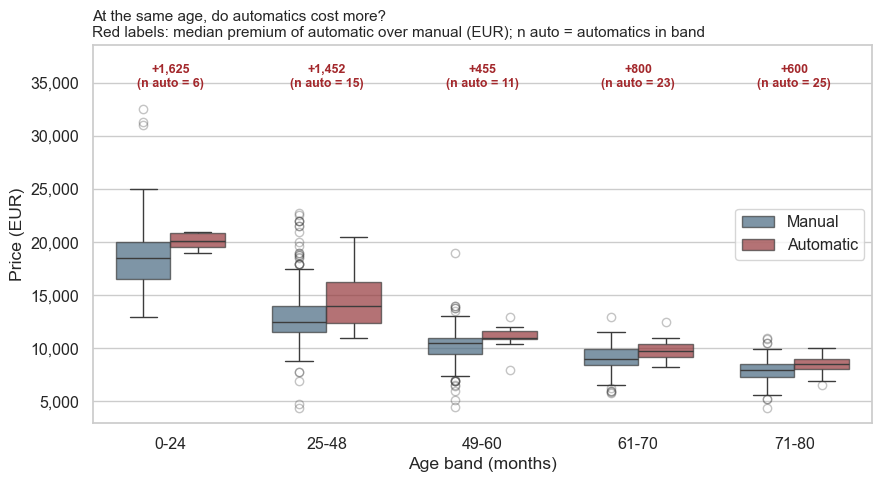

In [14]:
# Graph 3 (key graph): within every age band, automatic is more expensive
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=toyota, x="Age_band", y="Price", hue="Transmission",
            hue_order=ORDER, palette=TRANS_COLS, width=0.7,
            boxprops=dict(alpha=0.7), flierprops=dict(alpha=0.3), ax=ax)
n_auto = by_age_n.loc[age_wide.index, "Automatic"]
for i, (p, n) in enumerate(zip(age_wide.premium, n_auto)):
    ax.text(i, 34300, f"{p:+,.0f}\n(n auto = {n})", ha="center", va="bottom",
            color="#A3282C", fontweight="bold", fontsize=9)
ax.set_ylim(top=38500)
ax.yaxis.set_major_formatter(thousands)
ax.set(xlabel="Age band (months)", ylabel="Price (EUR)")
ax.set_title("At the same age, do automatics cost more?\n"
             "Red labels: median premium of automatic over manual (EUR); n auto = automatics in band",
             loc="left", fontsize=11)
ax.legend(title=None, loc="center right")
save(fig, "g3_price_by_age_band.png")

<div dir="rtl" style="background-color:#eef3f8; border-right:4px solid #3E6A8A; padding:10px 14px; border-radius:4px;">

**תובנה:** ברכב באותו גיל האוטומט יקר יותר בכל חמש הקבוצות, בפער חציוני של 455 עד 1,625 €.

הפרמיה הוסתרה בהשוואה הגולמית כי האוטומטיים מבוגרים יותר. בקבוצה הצעירה יש רק 6 אוטומטיים, ולכן הפרמיה של 1,625 € שם נשענת על מעט רכבים (רווחי סמך בהמשך).

</div>

<div dir="rtl">

**כמה יציבה הפרמיה?** בחלק מהקבוצות החציון של האוטומטיים נשען על מעט רכבים, ולכן מחשבים רווח סמך 95% ב־bootstrap להפרש החציונים.

</div>

In [15]:
def bootstrap_premium(df, band, n_boot=2000, seed=0):
    rng = np.random.default_rng(seed)
    rows = []
    for b, g in df.groupby(band, observed=True):
        man = g.loc[g.Transmission == "Manual", "Price"].to_numpy()
        aut = g.loc[g.Transmission == "Automatic", "Price"].to_numpy()
        if len(man) == 0 or len(aut) == 0:
            continue
        diffs = (np.median(rng.choice(aut, (n_boot, len(aut))), axis=1)
                 - np.median(rng.choice(man, (n_boot, len(man))), axis=1))
        lo, hi = np.percentile(diffs, [2.5, 97.5])
        rows.append({band: b, "n_auto": len(aut), "n_manual": len(man),
                     "premium": np.median(aut) - np.median(man),
                     "ci_low": lo, "ci_high": hi})
    return pd.DataFrame(rows).set_index(band).round(0)

display(bootstrap_premium(toyota, "Age_band"))

,n_auto,n_manual,premium,ci_low,ci_high
Age_band,,,,,
0-24,6,115,1625.0,550.0,2705.0
25-48,15,284,1452.0,-255.0,3550.0
49-60,11,279,455.0,250.0,1455.0
61-70,23,355,800.0,250.0,1000.0
71-80,25,322,600.0,400.0,1200.0


<div dir="rtl" style="background-color:#eef3f8; border-right:4px solid #3E6A8A; padding:10px 14px; border-radius:4px;">

**תובנה:** בארבע מחמש הקבוצות רווח הסמך כולו מעל אפס. בקבוצה הצעירה (0 עד 24) יש רק 6 אוטומטיים, ולכן הרווח רחב (550 עד 2,705 €). בקבוצת 25 עד 48 הרווח כולל את האפס (‎−255 עד 3,550 €), כך שהפרמיה שם לא יציבה. הכיוון עקבי בכל הקבוצות, אבל הגודל בכל קבוצה בנפרד לא מדויק.

</div>

<div dir="rtl">

**בדיקות רובוסטיות:** רק רכבי בנזין בטווח 86 עד 110 כ"ס (המנועים שבאמת מגיעים עם אוטומט), ובלי הק"מ החשוד.

</div>

In [16]:
fair = toyota[(toyota.Fuel_Type == "Petrol") & toyota.HP.between(86, 110)]
print("Petrol, 86-110 HP:"); display(premium_table(fair, "Age_band"))
print("Without suspicious KM:"); display(premium_table(toyota[~toyota.km_suspect], "Age_band"))

Petrol, 86-110 HP:


Transmission,Manual,Automatic,premium
Age_band,,,
0-24,18245.0,20125.0,1880.0
25-48,12450.0,13950.0,1500.0
49-60,10500.0,10972.5,472.5
61-70,9065.0,9750.0,685.0
71-80,7950.0,8500.0,550.0


Without suspicious KM:


Transmission,Manual,Automatic,premium
Age_band,,,
0-24,18500.0,20125.0,1625.0
25-48,12497.5,13950.0,1452.5
49-60,10497.5,10950.0,452.5
61-70,8950.0,9750.0,800.0
71-80,7900.0,8500.0,600.0


<div dir="rtl">

**רמת גימור ואחריות:** בקובץ יש משתני ציוד ואחריות. אם לאוטומטיים יש יותר ציוד או יותר אחריות, ייתכן שהפרמיה היא עליהם ולא על התיבה. הציוד קשור גם לגיל (למשל מחשב דרך), והאוטומטיים מבוגרים יותר, ולכן משווים גם בתוך קבוצות גיל (`diff_within_age_pp`, ממוצע משוקלל לפי מספר האוטומטיים בכל קבוצה).

</div>

In [17]:
equip_cols = ["ABS", "Airbag_1", "Airbag_2", "Airco", "Automatic_airco", "Boardcomputer",
              "CD_Player", "Central_Lock", "Powered_Windows", "Power_Steering", "Radio",
              "Mistlamps", "Sport_Model", "Metallic_Rim", "Met_Color", "Tow_Bar"]
# Equipment and warranty (warranty can also raise the price)
check_cols = [c for c in equip_cols + ["Mfr_Guarantee", "BOVAG_Guarantee"] if c in toyota.columns]
equip = (toyota.groupby("Transmission", observed=True)[check_cols].mean().T * 100).round(1)
equip["diff_pp"] = equip["Automatic"] - equip["Manual"]

# Equipment is linked to age (e.g. Boardcomputer), and automatics are older,
# so we also compare within age bands (weighted by the number of automatics in each band)
w = by_age_n["Automatic"]
def within_age_diff(col):
    g = toyota.groupby(["Age_band", "Transmission"], observed=True)[col].mean().unstack()
    return ((g["Automatic"] - g["Manual"]) * w).sum() / w.sum() * 100
equip["diff_within_age_pp"] = [round(within_age_diff(c), 1) for c in equip.index]
display(equip.sort_values("diff_within_age_pp"))
print("Guarantee_Period (months), median:",
      toyota.groupby("Transmission", observed=True).Guarantee_Period.median().to_dict())

Transmission,Manual,Automatic,diff_pp,diff_within_age_pp
Metallic_Rim,21.3,7.5,-13.8,-13.5
Met_Color,67.7,63.7,-4.0,-3.8
Airco,51.1,45.0,-6.1,-3.2
Boardcomputer,29.9,22.5,-7.4,-2.6
Radio,14.8,12.5,-2.3,-1.6
Airbag_1,97.1,96.2,-0.9,-0.7
Power_Steering,97.8,97.5,-0.3,-0.2
Powered_Windows,56.2,55.0,-1.2,0.0
CD_Player,21.9,20.0,-1.9,0.8
Central_Lock,58.0,57.5,-0.5,0.9


Guarantee_Period (months), median: {'Manual': 3.0, 'Automatic': 3.0}


<div dir="rtl" style="background-color:#eef3f8; border-right:4px solid #3E6A8A; padding:10px 14px; border-radius:4px;">

**תובנה:** גם בהשוואה בתוך קבוצות גיל אין לאוטומטיים יתרון בציוד, וההפרש הגדול ביותר הוא דווקא לטובת הידניים (חישוקי מתכת, ‎−13.5 נקודות אחוז).

בתוך קבוצות הגיל הפער במחשב דרך מצטמצם מ־‎−7.4 ל־‎−2.6 נקודות אחוז, כי הוא קשור לגיל. היתרונות הבולטים של האוטומטיים הם מזגן אוטומטי (+6.5) ואחריות יצרן (+7.1 נקודות אחוז). אחריות יכולה להעלות את המחיר, ולכן היא נכנסת כמשתנה בקרה ברגרסיה בסעיף 5.

</div>

<hr>

<div dir="rtl">

## 5. שאלת הסיבתיות: בקרה על ק"מ ועל כמה משתנים יחד

</div>

In [18]:
display(toyota.groupby(["KM_band", "Transmission"], observed=True).size().unstack(fill_value=0))
display(premium_table(toyota, "KM_band"))
print("Median KM by transmission:")
print(toyota.groupby("Transmission", observed=True).KM.median())
print("Median age (months) by KM band:")
display(toyota.groupby(["KM_band", "Transmission"], observed=True).Age_08_04.median().unstack())

Transmission,Manual,Automatic
KM_band,,
0-50K,449,33
50-100K,670,41
100-150K,184,6
150K+,52,0


Transmission,Manual,Automatic,premium
KM_band,,,
0-50K,12450.0,11950.0,-500.0
50-100K,9250.0,9800.0,550.0
100-150K,8450.0,8325.0,-125.0
150K+,6950.0,NaN,NaN


Median KM by transmission:
Transmission
Manual       64000.0
Automatic    56811.0
Name: KM, dtype: float64
Median age (months) by KM band:


Transmission,Manual,Automatic
KM_band,,
0-50K,41.0,47.0
50-100K,65.0,67.0
100-150K,68.0,74.5
150K+,69.5,NaN


<div dir="rtl">

**גרף 4:** פיזור של המחיר מול הגיל, רק לרכבי בנזין עם מנוע של 86 עד 110 כ"ס (המנועים שמגיעים גם עם אוטומט), עם קו מגמה ליניארי לכל סוג תיבה. מתחת לגרף מודפס הפער בין הקווים בגיל 24, 48 ו־80 חודשים.

</div>

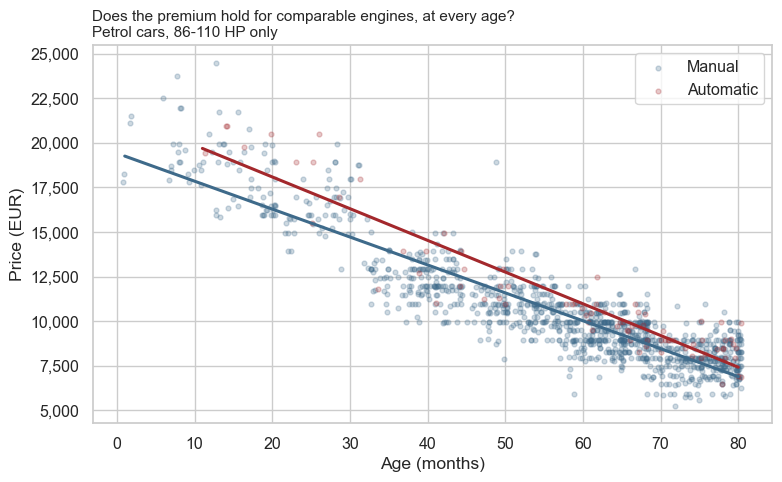

Gap (automatic - manual) at age 24 months: 1,717 EUR
Gap (automatic - manual) at age 48 months: 1,207 EUR
Gap (automatic - manual) at age 80 months: 527 EUR


In [19]:
# Graph 4: price vs age with a linear line per transmission (comparable engines)
fig, ax = plt.subplots(figsize=(8, 5))
rng = np.random.default_rng(1)
fits = {}  # intercept and slope per transmission
for t in ORDER:
    s = fair[fair.Transmission == t]
    ax.scatter(s.Age_08_04 + rng.uniform(-0.4, 0.4, len(s)), s.Price,
               alpha=0.25, s=12, color=TRANS_COLS[t], label=t)
    b, a = np.polyfit(s.Age_08_04, s.Price, 1)
    xs = np.array([s.Age_08_04.min(), s.Age_08_04.max()])
    ax.plot(xs, a + b * xs, color=TRANS_COLS[t], lw=2.2)
    fits[t] = (a, b)
ax.yaxis.set_major_formatter(thousands)
ax.set(xlabel="Age (months)", ylabel="Price (EUR)")
ax.set_title("Does the premium hold for comparable engines, at every age?\n"
             "Petrol cars, 86-110 HP only", loc="left", fontsize=11)
ax.legend()
save(fig, "g4_price_age_lines.png")

# Gap between the two lines at a few ages
for age in [24, 48, 80]:
    gap = (fits["Automatic"][0] + fits["Automatic"][1] * age) - (fits["Manual"][0] + fits["Manual"][1] * age)
    print(f"Gap (automatic - manual) at age {age} months: {gap:,.0f} EUR")

<div dir="rtl" style="background-color:#eef3f8; border-right:4px solid #3E6A8A; padding:10px 14px; border-radius:4px;">

**תובנה:** גם בין רכבי בנזין עם מנוע דומה (86 עד 110 כ"ס) האוטומט יקר יותר בכל גיל, והפער בין הקווים יורד מכ־1,700 € בגיל 24 חודשים לכ־530 € בגיל 80 חודשים.

כלומר הפרמיה לא מוסברת בהבדלי מנוע או דלק, והיא כנראה קטנה ככל שהרכב מתיישן. ברגרסיה עם אינטראקציה בין תיבה לגיל (סעיף 5) הירידה באותו כיוון אבל לא מובהקת (p = 0.41), ולכן זו מגמה ולא ממצא מוכח.

</div>

<div dir="rtl">

**גרף 5:** פיזור של הק"מ מול הגיל לכל הרכבים, עם עקומת LOWESS (קו מגמה מוחלק) לכל סוג תיבה. הגרף בודק אם האוטומטיים נוסעים פחות מהידניים באותו גיל.

</div>

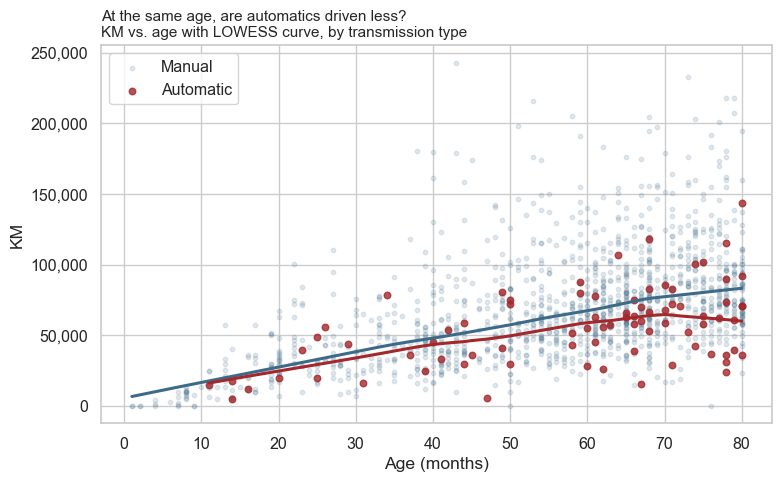

Median KM per month: {'Manual': 1143.0, 'Automatic': 931.0}


In [20]:
# Graph 5: the complication - automatics are older but driven less
fig, ax = plt.subplots(figsize=(8, 5))
for t, a, sz in [("Manual", 0.15, 10), ("Automatic", 0.8, 22)]:
    s = toyota[toyota.Transmission == t]
    ax.scatter(s.Age_08_04, s.KM, alpha=a, s=sz, color=TRANS_COLS[t], label=t)
    lo = lowess(s.KM, s.Age_08_04, frac=0.6)
    ax.plot(lo[:, 0], lo[:, 1], color=TRANS_COLS[t], lw=2.2)
ax.yaxis.set_major_formatter(thousands)
ax.set(xlabel="Age (months)", ylabel="KM")
ax.set_title("At the same age, are automatics driven less?\n"
             "KM vs. age with LOWESS curve, by transmission type", loc="left", fontsize=11)
ax.legend()
save(fig, "g5_age_km.png")
print("Median KM per month:", toyota.groupby("Transmission", observed=True).km_per_month.median().round(0).to_dict())

<div dir="rtl" style="background-color:#eef3f8; border-right:4px solid #3E6A8A; padding:10px 14px; border-radius:4px;">

**תובנה:** אוטומט נוסע בחציון 931 ק"מ בחודש לעומת 1,143 בידני, כ־19% פחות, ואין אף אוטומט מעל 150 אלף ק"מ.

עד גיל של כ־30 חודשים שתי הקבוצות נוסעות בערך אותו דבר, והפער נפתח מגיל זה ומעלה. לכן ייתכן שחלק מהפרמיה הוא על הק"מ הנמוך ולא על התיבה. הבדיקה בהמשך מפרידה בין השניים.

</div>

<div dir="rtl">

**בקרה על כמה משתנים יחד:** בתוך כל קבוצת ק"מ האוטומטיים שוב מבוגרים יותר (טבלת הגיל החציוני למעלה), כך שפיצול לפי ק"מ בלבד מערבב שוב את הגיל. לכן בודקים ברגרסיה שמבקרת על גיל וק"מ יחד (OLS, שגיאות תקן חסינות HC3). זו הצצה ראשונה לשיעור 4, לא מודל סופי.

**גרף 6:** הפרמיה של האוטומט (מקדם הרגרסיה) עם רווח סמך 95%, כשמוסיפים בכל שורה עוד משתני בקרה: בלי בקרה, גיל, ק"מ, הספק ודלק, ציוד ואחריות. הקו המקווקו הוא אפס, כלומר אין פרמיה.

</div>

,premium,ci_low,ci_high,p_value,R2
controls,,,,,
nothing,533.0,-291.0,1358.0,0.2049,0.001
age,966.0,662.0,1271.0,0.0000,0.772
age + km,712.0,408.0,1016.0,0.0000,0.792
age + km + hp + fuel,842.0,517.0,1167.0,0.0000,0.833
+ equipment + warranty,602.0,321.0,884.0,0.0000,0.874


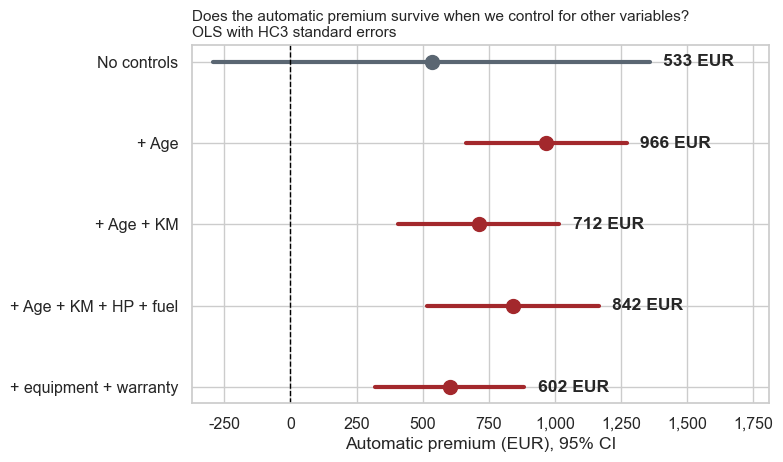

Interaction model:


,coef,p_value
Automatic,1349.6622,0.0584
Automatic:Age_08_04,-8.7290,0.4112


  premium at age 24 months: 1,140 EUR
  premium at age 48 months: 931 EUR
  premium at age 80 months: 651 EUR
Log-price model: premium = 7.1% (95% CI 4.6% to 9.7%)


In [21]:
models = {
    "nothing": "Price ~ Automatic",
    "age": "Price ~ Automatic + Age_08_04",
    "age + km": "Price ~ Automatic + Age_08_04 + KM",
    "age + km + hp + fuel": "Price ~ Automatic + Age_08_04 + KM + HP + C(Fuel_Type, Treatment('Petrol'))",
    "+ equipment + warranty": ("Price ~ Automatic + Age_08_04 + KM + HP + C(Fuel_Type, Treatment('Petrol'))"
                    " + Airco + Automatic_airco + ABS + Metallic_Rim + Boardcomputer"
                    " + Mfr_Guarantee + BOVAG_Guarantee"),
}
rows = []
for name, formula in models.items():
    m = smf.ols(formula, data=toyota).fit(cov_type="HC3")
    lo, hi = m.conf_int().loc["Automatic"]
    rows.append({"controls": name, "premium": m.params["Automatic"], "ci_low": lo,
                 "ci_high": hi, "p_value": m.pvalues["Automatic"], "R2": m.rsquared})
reg = pd.DataFrame(rows).set_index("controls")
display(reg.round({"premium": 0, "ci_low": 0, "ci_high": 0, "p_value": 4, "R2": 3}))


# Graph 6: how the premium changes as controls are added
fig, ax = plt.subplots(figsize=(8, 4.8))
labels = ["No controls", "+ Age", "+ Age + KM", "+ Age + KM + HP + fuel", "+ equipment + warranty"]
ypos = np.arange(len(reg))[::-1]
for y, (name, row) in zip(ypos, reg.iterrows()):
    c = "#5A6672" if name == "nothing" else TRANS_COLS["Automatic"]
    ax.plot([row.ci_low, row.ci_high], [y, y], color=c, lw=3)
    ax.plot(row.premium, y, "o", color=c, ms=10)
    ax.text(row.ci_high + 50, y, f"{row.premium:,.0f} EUR", va="center", fontweight="bold")
ax.axvline(0, color="black", lw=1, ls="--")
ax.set_yticks(ypos, labels)
ax.xaxis.set_major_formatter(thousands)
ax.set_xlim(right=reg.ci_high.max() + 450)
ax.set(xlabel="Automatic premium (EUR), 95% CI", ylabel=None)
ax.set_title("Does the automatic premium survive when we control for other variables?\n"
             "OLS with HC3 standard errors", loc="left", fontsize=11)
save(fig, "g6_premium_by_controls.png")

# Does the premium shrink with age? (interaction between transmission and age)
inter = smf.ols("Price ~ Automatic * Age_08_04 + KM + HP + C(Fuel_Type, Treatment('Petrol'))", data=toyota).fit(cov_type="HC3")
terms = ["Automatic", "Automatic:Age_08_04"]
print("Interaction model:")
display(pd.DataFrame({"coef": inter.params[terms], "p_value": inter.pvalues[terms]}).round(4))
for age in [24, 48, 80]:
    print(f"  premium at age {age} months: {inter.params['Automatic'] + inter.params['Automatic:Age_08_04'] * age:,.0f} EUR")

# Premium in percent (log price)
logm = smf.ols("np.log(Price) ~ Automatic + Age_08_04 + KM + HP + C(Fuel_Type, Treatment('Petrol'))", data=toyota).fit(cov_type="HC3")
lo, hi = logm.conf_int().loc["Automatic"]
print(f"Log-price model: premium = {np.expm1(logm.params['Automatic']):.1%} "
      f"(95% CI {np.expm1(lo):.1%} to {np.expm1(hi):.1%})")

<div dir="rtl" style="background-color:#eef3f8; border-right:4px solid #3E6A8A; padding:10px 14px; border-radius:4px;">

**תובנה:** כשמבקרים ברגרסיה על גיל וק"מ יחד נשארת פרמיה של 712 € (רווח סמך 408 עד 1,016 €), ואחרי בקרה גם על הספק, דלק, ציוד ואחריות נשארת פרמיה של 602 € (321 עד 884 €).

כשמפצלים לפי ק"מ הפרמיה נראית לא עקבית, אבל זה אותו ערבוב שראינו בגיל: בתוך כל קבוצת ק"מ האוטומטיים מבוגרים יותר (למשל 47 מול 41 חודשים בקבוצת 0 עד 50 אלף), והגיל מסתיר שוב את הפרמיה.

**הפרמיה באחוזים:** במודל עם לוגריתם המחיר האוטומט יקר ב־7.1% (רווח סמך 4.6% עד 9.7%) מרכב ידני עם אותו גיל, ק"מ, הספק ודלק.

**האם הפרמיה קטנה עם הגיל?** במודל עם אינטראקציה הפרמיה המוערכת יורדת מכ־1,140 € בגיל 24 חודשים לכ־650 € בגיל 80, אבל האינטראקציה לא מובהקת (p = 0.41). עם 80 אוטומטיים בלבד אין מספיק נתונים כדי לקבוע זאת.

**חציון מול ממוצע:** בסעיף 4 הפרמיה היא הפרש חציונים בתוך קבוצת גיל, וכאן היא מקדם רגרסיה, כלומר הפרש ממוצעים אחרי בקרה. לכן המספרים לא זהים, אבל שתי השיטות מראות פרמיה חיובית באותו סדר גודל.

**השערה:** חלק מהפרמיה מוסבר בק"מ הנמוך, אבל לא כולה, והיא נשארת חיובית אחרי כל הבקרות. לא ברור אם KM הוא משתנה מתערב או משתנה מתווך (מי שקונה אוטומט נוסע פחות, ולכן הרכב שומר על ערכו). אם הוא מתווך, הבקרה עליו מורידה חלק מהאפקט של התיבה. לכן הפרמיה מוערכת בין כ־600 ל־970 €, כ־7% מהמחיר. זו הערכה מתוך נתוני תצפית ולא הוכחה סיבתית (ראו סעיפים 8 ו־9).

</div>

<hr>

<div dir="rtl">

## 6. הכנה למודל (שלב 7, נספח לשיעור 4)
הכנת הנתונים למודלים של שיעור 4: קידוד, החלטה על Scaling, וחלוקה ל־Train/Test.

</div>

In [22]:
# Variables of the prediction question
model_df = toyota[["Price", "Age_08_04", "KM", "HP", "Automatic", "Weight", "Doors", "Fuel_Type"]]
# Petrol (the most common fuel) is the reference category
model_df = pd.get_dummies(model_df, columns=["Fuel_Type"], dtype=int).drop(columns="Fuel_Type_Petrol")

# 80/20 split, stratified by transmission (only 80 automatics)
train = model_df.groupby("Automatic", group_keys=False).sample(frac=0.8, random_state=42)
test = model_df.drop(train.index)
print("Train:", train.shape, " Test:", test.shape)
print(f"Automatic share - train: {train.Automatic.mean():.1%}, test: {test.Automatic.mean():.1%}")
display(model_df.head())
# Correlation between the predictors and with Price
display(model_df.corr().round(2))

Train: (1148, 9)  Test: (287, 9)
Automatic share - train: 5.6%, test: 5.6%


,Price,Age_08_04,KM,HP,Automatic,Weight,Doors,Fuel_Type_CNG,Fuel_Type_Diesel
0,13500,23,46986,90,0,1165,3,0,1
1,13750,23,72937,90,0,1165,3,0,1
2,13950,24,41711,90,0,1165,3,0,1
3,14950,26,48000,90,0,1165,3,0,1
4,13750,30,38500,90,0,1170,3,0,1


,Price,Age_08_04,KM,HP,Automatic,Weight,Doors,Fuel_Type_CNG,Fuel_Type_Diesel
Price,1.00,-0.88,-0.57,0.31,0.03,0.58,0.18,-0.04,0.05
Age_08_04,-0.88,1.00,0.50,-0.16,0.03,-0.47,-0.15,0.00,-0.09
KM,-0.57,0.50,1.00,-0.33,-0.08,-0.02,-0.04,0.14,0.41
HP,0.31,-0.16,-0.33,1.00,0.01,0.09,0.09,0.06,-0.54
Automatic,0.03,0.03,-0.08,0.01,1.00,0.06,-0.03,0.00,-0.08
Weight,0.58,-0.47,-0.02,0.09,0.06,1.00,0.30,0.05,0.56
Doors,0.18,-0.15,-0.04,0.09,-0.03,0.30,1.00,0.01,0.02
Fuel_Type_CNG,-0.04,0.00,0.14,0.06,0.00,0.05,0.01,1.00,-0.04
Fuel_Type_Diesel,0.05,-0.09,0.41,-0.54,-0.08,0.56,0.02,-0.04,1.00


<div dir="rtl" style="background-color:#faf3f3; border-right:4px solid #A3282C; padding:10px 14px; border-radius:4px;">

**החלטות:**
- Fuel_Type מקודד ב־One-Hot Encoding, כי אלה קטגוריות בלי סדר (Label Encoding היה יוצר סדר מלאכותי). קטגוריה אחת יורדת כקטגוריית בסיס.
- Automatic כבר משתנה 0/1, ואין צורך לקודד אותו. Doors נשאר מספרי (2 עד 5 דלתות).
- לא מבצעים Scaling. ברגרסיה ליניארית הוא לא משנה את התחזיות, ובלעדיו המקדמים נשארים ביחידות של € לחודש, לק"מ, לכ"ס ולק"ג. הוא יידרש רק במודלים מבוססי מרחק (KNN) או עם רגולריזציה.
- החלוקה היא 80/20, מרובדת לפי סוג התיבה. יש רק 80 אוטומטיים, ובלי ריבוד שיעורם ב־test עלול לצאת שונה מאוד.
- טבלת המתאמים: הקשר החזק ביותר למחיר הוא גיל (‎−0.88), אחריו משקל (0.58) וק"מ (‎−0.57). Automatic כמעט לא מתואם עם המחיר (0.03), כך שתרומתו לחיזוי תלויה בבקרה על גיל. משקל קשור לדיזל (0.56), וקטגוריית הבסיס של הדלק היא Petrol, הנפוצה ביותר (1,264 רכבים), כך שהמקדמים של דיזל ו־CNG מושווים לרכב הטיפוסי. CNG כולל רק 17 רכבים, ולכן המקדם שלו יהיה לא יציב.
- הרכב עם המשקל החשוד (Id 223) נשאר ב־model_df ומסומן ב־`weight_suspect`, כדי לבדוק בשיעור 4 אם הוא משפיע על המקדם של Weight.
- בשיעור 4 כדאי להוסיף Cross-Validation, שנותן הערכה יציבה יותר מחלוקה אחת במדגם קטן כזה.

</div>

<hr>

<div dir="rtl">

## 7. השערות להמשך
| # | השערה | על סמך |
|---|---|---|
| 1 | H₀: באותה קבוצת גיל חציון המחיר של אוטומט שווה לזה של ידני. H₁: האוטומט יקר יותר. | גרף 3, רווחי סמך ב־bootstrap |
| 2 | H₀: הפרמיה נעלמת אחרי בקרה על גיל, ק"מ, הספק, דלק, ציוד ואחריות. H₁: הפרמיה נשארת. | גרפים 4 ו־5, רגרסיה בסעיף 5 |
| 3 | H₀: הפרמיה זהה בכל גיל. H₁: הפרמיה קטנה ככל שהרכב מתבגר. | גרף 4 (מגמה לא מובהקת במדגם הזה) |
| 4 | H₀: הוספת Automatic למודל עם גיל, ק"מ, הספק, משקל, דלתות ודלק לא משפרת את דיוק החיזוי. H₁: היא משפרת אותו. | טבלת המתאמים בסעיף 6 |

## 8. מה הנתונים לא מאפשרים לדעת
| מגבלה | מה זה משנה במסקנה |
|---|---|
| רק 80 אוטומטיים, ובקבוצת הגיל הצעירה רק 6. | רווחי הסמך רחבים. את הפרמיה ברכב צעיר (1,625 €) אי אפשר לאמוד בדיוק, וגם לא לקבוע אם הפרמיה קטנה עם הגיל. |
| מחיר מבוקש ולא מחיר עסקה. | ייתכן שהפרמיה קיימת רק במודעה ונשחקת במשא ומתן, כך שהקונה עשוי לשלם בפועל פחות ממנה. |
| לא ידוע איזו תיבה זו: 76 מתוך 80 האוטומטיים רשומים עם 5 הילוכים, אולי תיבה רובוטית. | הממצא חל על האוטומטיים שבמדגם, ואי אפשר להכליל אותו לאוטומט קלאסי. |
| מנוע 107 כ"ס קיים רק באוטומט, ואין אוטומט בדיזל. | את השפעת המנוע הזה אי אפשר להפריד מהתיבה, והממצא לא חל על קונה שמחפש דיזל. |
| מתערבים שלא נמדדו: סוג המוכר (סוחר או פרטי), היסטוריית תאונות וטיפולים, מספר בעלים, מצב הרכב, רמת גימור מלאה. | אם, למשל, אוטומטיים נמכרים יותר אצל סוחרים שגובים יותר, חלק מהפרמיה הוא על המוכר ולא על התיבה. לכן אי אפשר לקבוע שהתיבה עצמה גורמת לפער. |
| אין זמן עד מכירה. | לא ידוע אם אוטומט נמכר מהר יותר, ולכן אי אפשר לומר אם השוק באמת מוכן לשלם את הפרמיה. |
| קורולה בלבד, הולנד, 2004. | בשוק שבו אוטומט נפוץ יותר, או בדגמים אחרים, הפרמיה עשויה להיות שונה לגמרי. |

## 9. סיכום לבעל העניין

**מה הייתי אומר לקונה:** בנתונים האלה אוטומט מבוקש בכ־600 עד 1,000 € יותר מרכב ידני באותו גיל, כ־7% מהמחיר, וכנראה יותר ברכב צעיר. כשמשווים מודעות צריך להשוות רכבים באותו גיל, כי אוטומט נראה זול רק משום שהוא בדרך כלל מבוגר יותר. לאוטומטיים יש גם פחות ק"מ (כ־19% פחות בחודש), כך שחלק ממה שמשלמים עליו הוא רכב שנסע פחות. אלה מחירים מבוקשים, ולכן יש מקום להתמקח על הפרמיה.

### תשובות לשאלות המחקר
| סוג | תשובה | איפה |
|---|---|---|
| תיאור | 94.4% מהרכבים ידניים (1,355) ו־5.6% אוטומטיים (80). חציון המחיר כמעט זהה: 9,900 € לידני ו־9,950 € לאוטומט. | 3, גרף 1 |
| קשר | בהשוואה הגולמית אין קשר (פער של 533 €, p = 0.20). בתוך כל קבוצת גיל האוטומט יקר יותר, בפער של 455 עד 1,625 €, כי האוטומטיים מבוגרים יותר והגיל הסתיר את הפער. | 3, 4, גרפים 2 ו־3 |
| חיזוי | **השערה:** גיל, ק"מ, הספק ומשקל יחזו את המחיר היטב, ו־Automatic יוסיף מעט (מתאם של 0.03 בלבד עם המחיר). על סמך טבלת המתאמים ורגרסיה ראשונית שמסבירה 83% עד 87% מהשונות. **נדרש:** מודל שנבנה על Train ונבדק על רכבים שלא ראה (Test), בשיעור 4. | 5, 6 |
| סיבתיות | **השערה:** חלק מהפער נובע מהתיבה עצמה, כי הוא נשאר בתוך כל קבוצת גיל (גרף 3), בין מנועים דומים (גרף 4), ואחרי בקרה על ק"מ, ציוד ואחריות (כ־600 עד 970 €). **נדרש:** נתונים על סוג המוכר, תאונות ומספר בעלים, או השוואה של אותו דגם בשתי הגרסאות אצל אותו מוכר. בלי זה אי אפשר לשלול מתערבים שלא נמדדו. | 4, 5, 8 |

</div>